# Polar-vortex (SSW) diagnostics

## Purpose

Show how the initial atmosphere and land states affect the simulated 2012-13 northern polar vortex (major SSW in January 2013). Every figure uses ERA5 and ERA-Interim together: lines are the mean over the references, bands and whiskers their half-range.

## Inputs

Model: the 2012-2013 AMIP hindcasts under `INPUT_DATA_ROOT/<case>/post/atm/180x360_aave` (experiments and initial states in `configs/hind_experiment_config.py`). Monthly `ua`, `ta`, `zg` (`cmip_ts/monthly`). References: ERA5, ERA-Interim monthly (E3SM Diags time series under `OBSERVATION_ROOT`), read lazily north of 50N on the model levels.

## Method

Zonal means, then cos-lat weighted means: U over 55-65N (`u_55_65N`) and 55-75N (`u_vortex`), Z and T over 60-90N (`z_pcap`, `t_pcap`). Against each reference: bias series and RMSE profiles over all months, DJF, the SSW season (`SSW_START`-`SSW_END`), and lead-month windows from January 2012 (lead 0). Scores: RMSE change relative to CTRL by initial-state component (total vs CTRL, land effect, DA − ERA5) at `ATTRIBUTION_LEVEL`, against the 95% noise floor of a difference of two single runs (t·√2·σ, σ the interaction residual of the additive atm + lnd fit of the RMSEs, `util/hind_factorial.py`), and the factorial effects of each window's RMSE.

The January 2013 SSW is ~12 months after the initial date, beyond deterministic predictability, so a single run's vortex RMSE there is mostly chance. The 8 runs are therefore also read as a pseudo-ensemble of the forced model, together with the plausible pathway from the initial state: the equatorial QBO wind at `QBO_LEVEL` in the same winter (Holton-Tan: an easterly lower-stratospheric QBO favours a weak vortex; QBO sections from notebook 01). Monthly means smooth the event: the reanalysis January-2013 mean of U(55-65N, 10 hPa) is ~0.

## Outputs

`data/hind_atm_eval/ssw/ssw_monthly_<SOURCE>_vs_<REF>.nc` (a reference's own indices: `_<REF>_vs_<REF>`), `ssw_attribution_u_<level>hPa.csv`, `ssw_winter_table.csv`, `ssw_rmse_effects.csv`; figures in `figure/hind_atm_eval/ssw/`:

1. Bias of U(55-65N), polar-cap Z and T at 10 and 100 hPa.
2. U bias and `RUNNING_RMSE_MONTHS`-month running RMSE.
3. RMSE attribution for `ATTRIBUTION_WINDOWS`.
4. Raw index evolution with both references and correlations.
5. Winter RMSE profiles.
6. Pseudo-ensemble of the vortex and winter-mean vortex vs QBO wind (Holton-Tan).
7. Factorial scorecard of the U RMSE per window.

## 1. Libraries

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import xarray as xr
from IPython.display import display

## 2. User setup

Paths and run options. Edit this cell for normal changes; it holds plain values only, so `papermill -p` overrides work.

In [2]:
INPUT_DATA_ROOT = Path("/global/cfs/cdirs/m4849/zhan391/eam_hindcast")
WORK_DIR = Path("/global/cfs/cdirs/m4849/zhan391/work_package/e3sm_dart_analysis")
DIAGNOSTIC_OUTPUT_ROOT = Path("/global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026")
OBSERVATION_ROOT = Path("/global/cfs/cdirs/e3sm/zhan391/data")  # reference-data archive
WORKFLOW_NAME = "hind_atm_eval"

# Experiments: run key (file names, tables) -> figure label. Labels follow fcst_atm_eval: the experiment
# whose initial state the run starts from (CTRL10: piControl, CAPT10: ERA5, DART40: DART), written
# "<atm>A-<lnd>L" when atmosphere and land come from different ones. EXPERIMENTS_FULL (backup) is the full
# atm x lnd factorial, needed for the initial-state attribution (factorial effects and noise floors).
EXPERIMENTS_FULL = {
    "CTRL": "CTRL10-S0",           # piControl atm + piControl lnd
    "DARTOP": "DART40-S0",         # DART atm + DART lnd
    "ERA5OP": "CAPT10-S0",         # ERA5 atm + ERA5-forced lnd
    "ERA5DL": "CAPTA-DARTL-S0",    # ERA5 atm + DART lnd
    "ERA5BL": "CAPTA-CTRLL-S0",    # ERA5 atm + piControl lnd
    "DARTBL": "DARTA-CTRLL-S0",    # DART atm + piControl lnd
    "DARTBA": "CTRLA-DARTL-S0",    # piControl atm + DART lnd
    "DARTAE": "DARTA-CAPTL-S0",    # DART atm + ERA5-forced lnd
}
EXPERIMENTS_FCST = {k: EXPERIMENTS_FULL[k] for k in ("CTRL", "ERA5OP", "DARTOP")}
EXPERIMENTS = EXPERIMENTS_FCST  # or EXPERIMENTS_FULL
REFERENCES = ("ERA5", "ERAI")
SSW_START = (2012, 11)
SSW_END = (2013, 3)
LEAD_WINDOWS = ((0, 3), (0, 6), (10, 14))  # lead months, inclusive
ATTRIBUTION_LEVEL = 10.0                   # hPa
ATTRIBUTION_WINDOWS = ((0, 6), "ssw")      # lead months or "ssw" / "winter" / "all"
RUNNING_RMSE_MONTHS = 3
WINTER = ("2012-12", "2013-02")            # winter for the pseudo-ensemble and Holton-Tan
QBO_LEVEL = 50.0                           # hPa; QBO sections of 01_compute_and_plot_qbo.ipynb
SCORE_WINDOWS = ((0, 3), (0, 6), "ssw", "winter")
FORCE_COMPUTE = False
SHOW = True
FIGURE_DPI = 300
USE_DISTRIBUTED = False  # True: local dask.distributed cluster; worker processes read files in parallel
DASK_WORKERS = 8         # threads (threaded scheduler) or worker processes (distributed); bounds memory

## 3. Paths and modules

In [3]:
repo = WORK_DIR.resolve()
if str(repo / "diagnostic") not in sys.path:
    sys.path.insert(0, str(repo / "diagnostic"))
from configs.output_paths import workflow_output_dirs
from util.dask_helpers import compute_all, configure_dask
from util.hind_factorial import relabel_figure

client = configure_dask(use_distributed=USE_DISTRIBUTED, n_workers=DASK_WORKERS, n_threads=DASK_WORKERS)
data_dir, figure_dir = workflow_output_dirs(WORKFLOW_NAME, 'ssw', output_root=DIAGNOSTIC_OUTPUT_ROOT)
ROOTS = dict(observation_root=OBSERVATION_ROOT)
FACTORIAL = set(EXPERIMENTS) == set(EXPERIMENTS_FULL)  # the atm x lnd attribution needs all 8 runs
SET_NAME = "full" if FACTORIAL else "fcst_aligned" if set(EXPERIMENTS) == set(EXPERIMENTS_FCST) else "subset"
table_dir = data_dir
if not FACTORIAL:  # tables and figures of a subset kept apart from the full set; per-source files are shared
    table_dir, figure_dir = data_dir / SET_NAME, figure_dir / SET_NAME
    for d in (table_dir, figure_dir):
        d.mkdir(exist_ok=True)
print(f"[DATA] {data_dir}\n[TABLE] {table_dir}\n[FIGURE] {figure_dir}")

def save(fig, name):
    relabel_figure(fig, EXPERIMENTS_FULL)  # run keys -> figure labels
    path = figure_dir / name
    fig.savefig(path, dpi=FIGURE_DPI, bbox_inches="tight")
    print(f"[FIGURE] {path}")
    if not SHOW:
        plt.close(fig)

[DATA] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_atm_eval/ssw
[TABLE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_atm_eval/ssw/fcst_aligned
[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_eval/ssw/fcst_aligned


## 4. Read input

Saved diagnostics are reused: fields are opened lazily only for the sources whose output file is missing (all of them with `FORCE_COMPUTE`), and loaded in the Derive step. An experiment is read when any of its comparison files is missing.

In [4]:
from util.ssw_diagnostics import open_ssw_input, ssw_path

ref_paths = {r: ssw_path(data_dir, r, r) for r in REFERENCES}
exp_paths = {(e, r): ssw_path(data_dir, e, r) for e in EXPERIMENTS for r in REFERENCES}
todo = [r for r in REFERENCES if FORCE_COMPUTE or not ref_paths[r].exists()]
todo += [e for e in EXPERIMENTS if FORCE_COMPUTE or not all(exp_paths[e, r].exists() for r in REFERENCES)]
inputs = {s: open_ssw_input(s, data_root=INPUT_DATA_ROOT, **ROOTS) for s in todo}
print(f"[READ] {', '.join(inputs) or 'nothing: every index file is saved'}")

[READ] nothing: every index file is saved


## 5. Derive

Indices of every source read, then each experiment's biases and RMSEs against each reference. The expensive reductions of every source are computed together in one Dask graph (`compute_all`), so reads and reductions run in parallel; the rest works on the loaded results.

In [5]:
from util.ssw_diagnostics import SswAnalyzer, SswConfig

analyzer = SswAnalyzer(SswConfig(ssw_start=SSW_START, ssw_end=SSW_END, lead_windows=LEAD_WINDOWS))
indices = compute_all({s: analyzer.compute_indices(**fields, name=s, compute=False) for s, fields in inputs.items()})
ref_indices = {r: indices[r] if r in indices else xr.load_dataset(ref_paths[r]) for r in REFERENCES}
compared = {(e, r): analyzer.compare_to_reference(indices[e], ref_indices[r], r)
            for e in indices if e not in REFERENCES for r in REFERENCES}

Warning 3: Cannot find header.dxf (GDAL_DATA is not defined)
ERROR 1: PROJ: proj_create_from_database: Cannot find proj.db


## 6. Save

Write the newly derived files, then reload every source from disk so the steps below use the same data as a rerun that reuses the files. Check: 10-hPa U(55-65N) RMSE over the SSW season vs each reference.

In [6]:
for r in REFERENCES:
    if r in indices:
        indices[r].assign_attrs(role="reference").to_netcdf(ref_paths[r])
        print(f"[WRITE] {ref_paths[r]}")
for key, ds in compared.items():
    ds.to_netcdf(exp_paths[key])
    print(f"[WRITE] {exp_paths[key]}")
display(xr.Dataset({r: xr.concat([xr.load_dataset(exp_paths[e, r])[f"u_55_65N_rmse_ssw_{r}"].sel(plev=1000.0)
                                  for e in EXPERIMENTS], "experiment")
                    .assign_coords(experiment=list(EXPERIMENTS)) for r in REFERENCES}).to_dataframe().round(2))

,plev,ERA5,ERAI
experiment,,,
CTRL,1000.0,16.10,16.10
ERA5OP,1000.0,14.55,14.61
DARTOP,1000.0,12.83,13.01


## 7. Scores

RMSE attribution of U(55-65N) at `ATTRIBUTION_LEVEL` (% of CTRL's RMSE; mean and half-range over the references; `noise95`: noise floor of a two-run difference); factorial effects of the RMSE per window; winter vortex and QBO phase per source.

In [7]:
import pandas as pd

from configs.output_paths import workflow_output_dirs
from util.hind_factorial import factorial_effects
from util.ssw_plotting import SswPlotter

ssw_window = tuple(f"{y}-{m:02d}" for y, m in (SSW_START, SSW_END))
plotter = SswPlotter(data_dir, EXPERIMENTS, REFERENCES, ssw_window=ssw_window, font_scale=12)
attribution = plotter.rmse_attribution_table(p_hpa=ATTRIBUTION_LEVEL, windows=ATTRIBUTION_WINDOWS)
out = table_dir / f"ssw_attribution_u_{ATTRIBUTION_LEVEL:g}hPa.csv"
attribution.to_csv(out, index=False)
print(f"[WRITE] {out}")
display(attribution.round(1))

label = lambda w: w if isinstance(w, str) else f"lead{w[0]}-{w[1]}"
rmse_scores = pd.DataFrame({f"RMSE {label(w)}": {e: sum(plotter.rmse(e, r, "u_55_65N", ATTRIBUTION_LEVEL, w)
                                                       for r in REFERENCES) / len(REFERENCES) for e in EXPERIMENTS}
                            for w in SCORE_WINDOWS})
if FACTORIAL:
    effects = factorial_effects(rmse_scores)
    effects.to_csv(table_dir / "ssw_rmse_effects.csv", index=False)
    print(f"[WRITE] {table_dir / 'ssw_rmse_effects.csv'}")
    display(effects.pivot_table(index="metric", columns="effect", values="estimate", sort=False).round(2))
else:
    print(f"[SKIP] factorial effects: need EXPERIMENTS_FULL (EXPERIMENTS is {SET_NAME})")

qbo_dir, _ = workflow_output_dirs(WORKFLOW_NAME, "qbo", output_root=DIAGNOSTIC_OUTPUT_ROOT)
winter = plotter.winter_table(qbo_dir, p_hpa=ATTRIBUTION_LEVEL, winter=WINTER, qbo_level=QBO_LEVEL)
winter.to_csv(table_dir / "ssw_winter_table.csv")
print(f"[WRITE] {table_dir / 'ssw_winter_table.csv'}")
display(winter)

[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_atm_eval/ssw/fcst_aligned/ssw_attribution_u_10hPa.csv


,window,group,bar,minuend,subtrahend,value,ref_halfrange,noise95,exceeds_noise
0,"(0, 6)",Total vs CTRL,ERA5(atm+lnd),ERA5OP,CTRL,-17.5,0.1,NaN,False
1,"(0, 6)",Total vs CTRL,DART(atm+lnd),DARTOP,CTRL,-26.2,1.4,NaN,False
2,"(0, 6)",DA − ERA5,DART − ERA5,DARTOP,ERA5OP,-8.7,1.5,NaN,False
3,ssw,Total vs CTRL,ERA5(atm+lnd),ERA5OP,CTRL,-9.4,0.2,NaN,False
4,ssw,Total vs CTRL,DART(atm+lnd),DARTOP,CTRL,-19.8,0.6,NaN,False
5,ssw,DA − ERA5,DART − ERA5,DARTOP,ERA5OP,-10.3,0.4,NaN,False


[SKIP] factorial effects: need EXPERIMENTS_FULL (EXPERIMENTS is fcst_aligned)


[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_atm_eval/ssw/fcst_aligned/ssw_winter_table.csv


,winter_mean,ssw_min,ssw_min_month,easterly_months,qbo50_winter
source,,,,,
ERA5,12.809859,0.020432,2013-01,0,-14.839288
ERAI,12.511945,-0.028420,2013-01,1,-15.556958
CTRL,25.478244,11.380996,2013-03,0,13.578817
ERA5OP,24.046173,20.846309,2013-03,0,14.142366
DARTOP,25.622195,14.867999,2013-01,0,12.022740


## 8. Plot and show

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_eval/ssw/fcst_aligned/ssw_bias_timeseries.png


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_eval/ssw/fcst_aligned/ssw_u_bias_running_rmse.png


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_eval/ssw/fcst_aligned/ssw_attribution_u_10hPa.png


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_eval/ssw/fcst_aligned/ssw_evolution_10hPa.png


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_eval/ssw/fcst_aligned/ssw_evolution_100hPa.png


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_eval/ssw/fcst_aligned/ssw_rmse_profiles_winter.png


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_eval/ssw/fcst_aligned/ssw_pseudo_ensemble.png


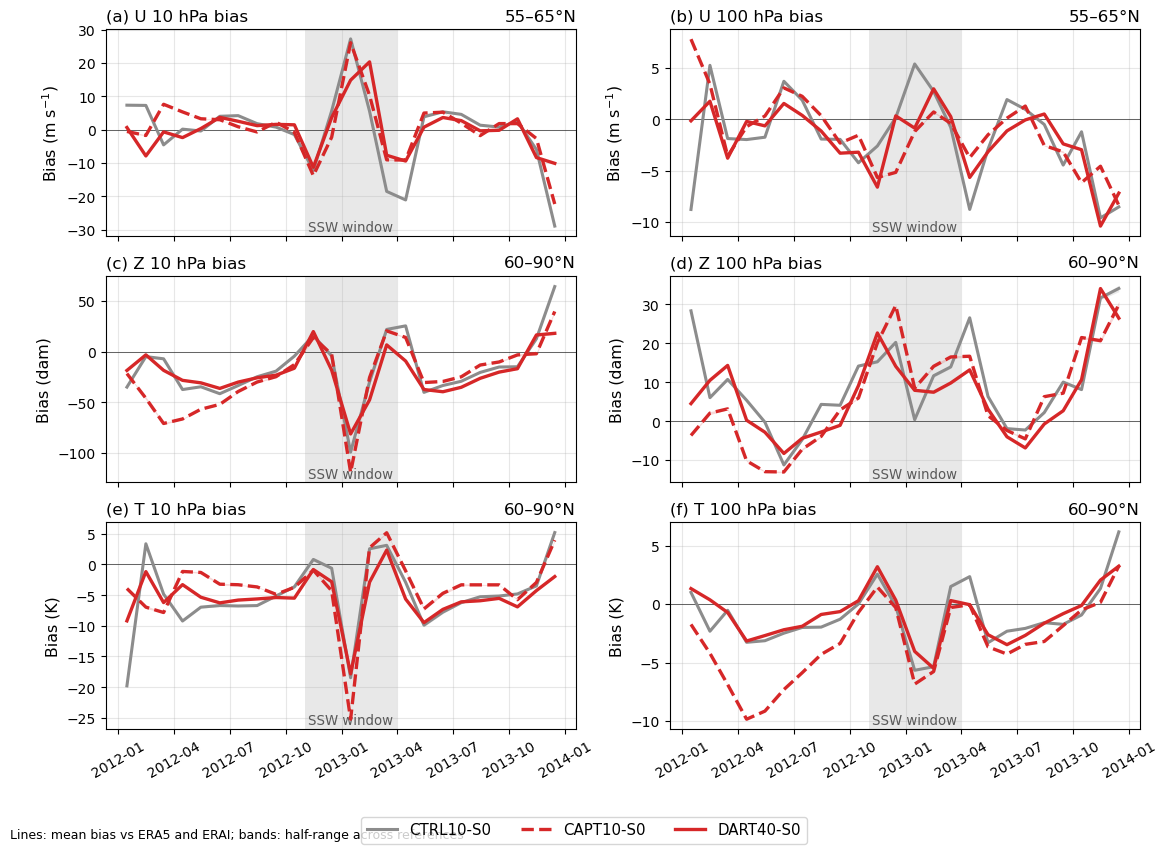

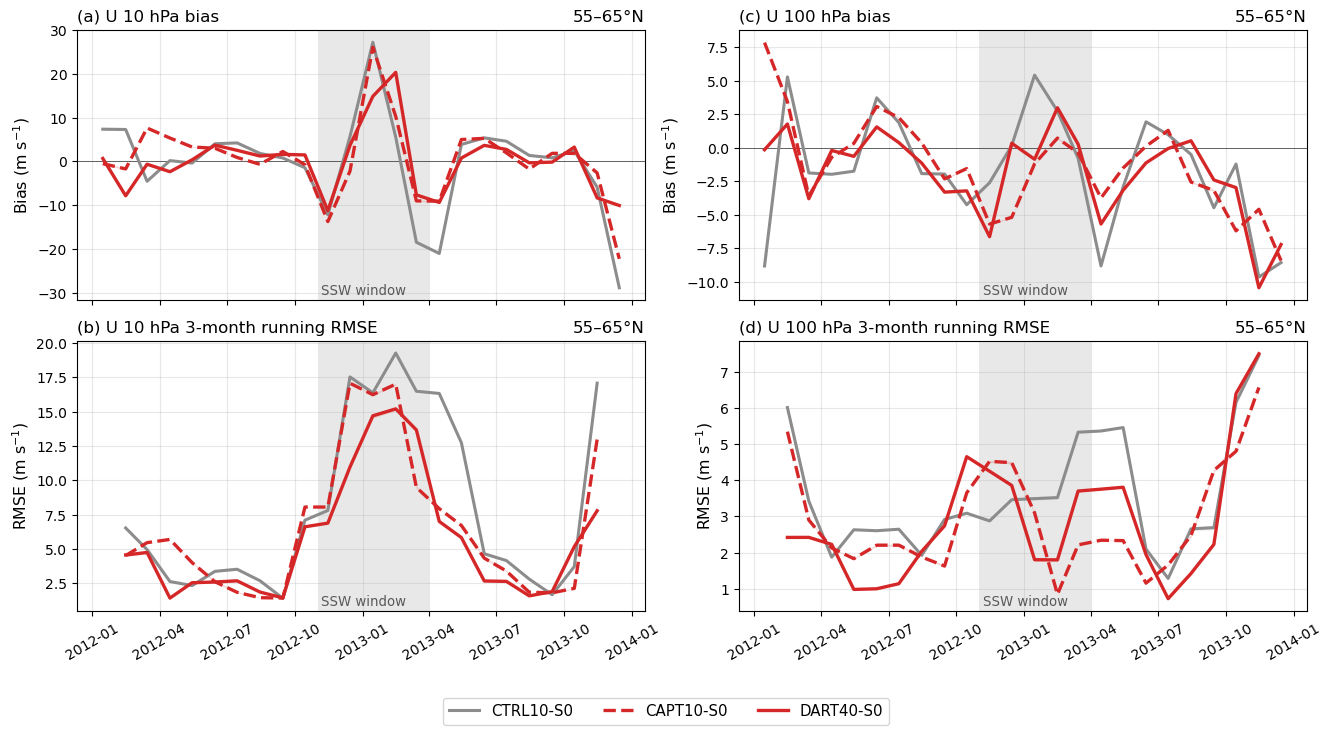

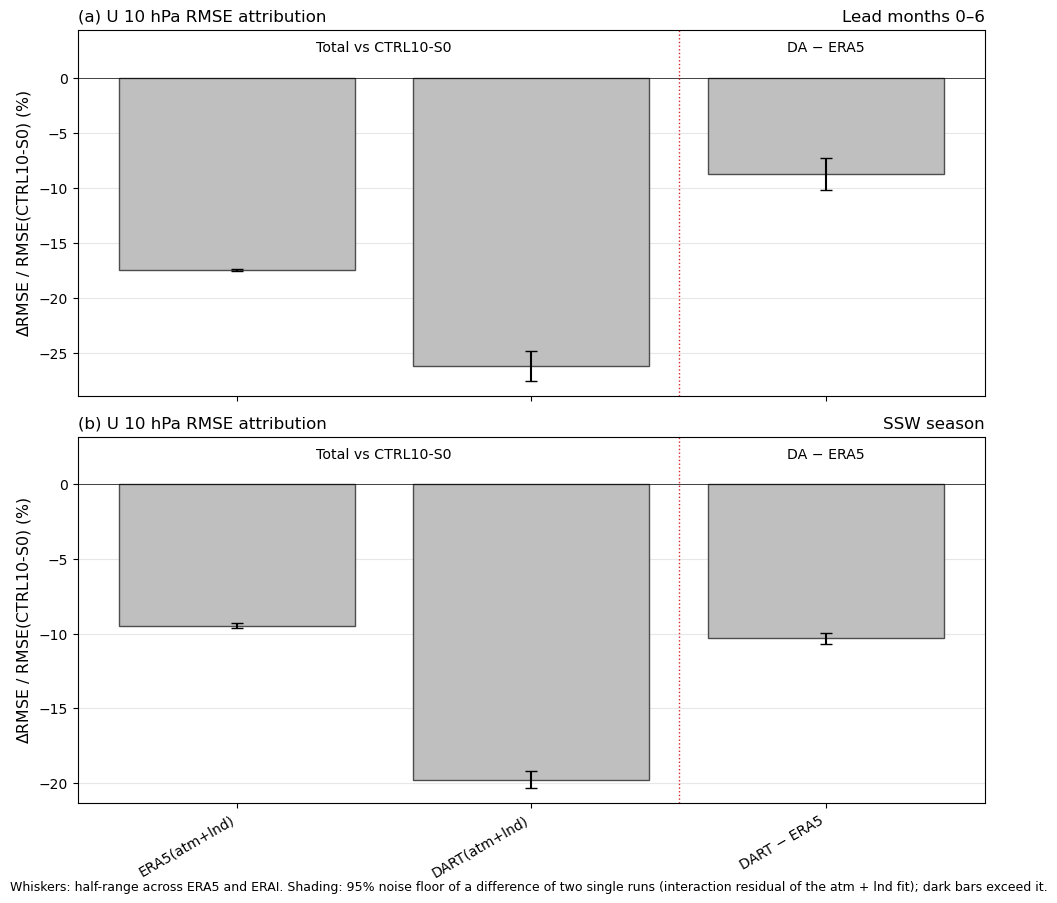

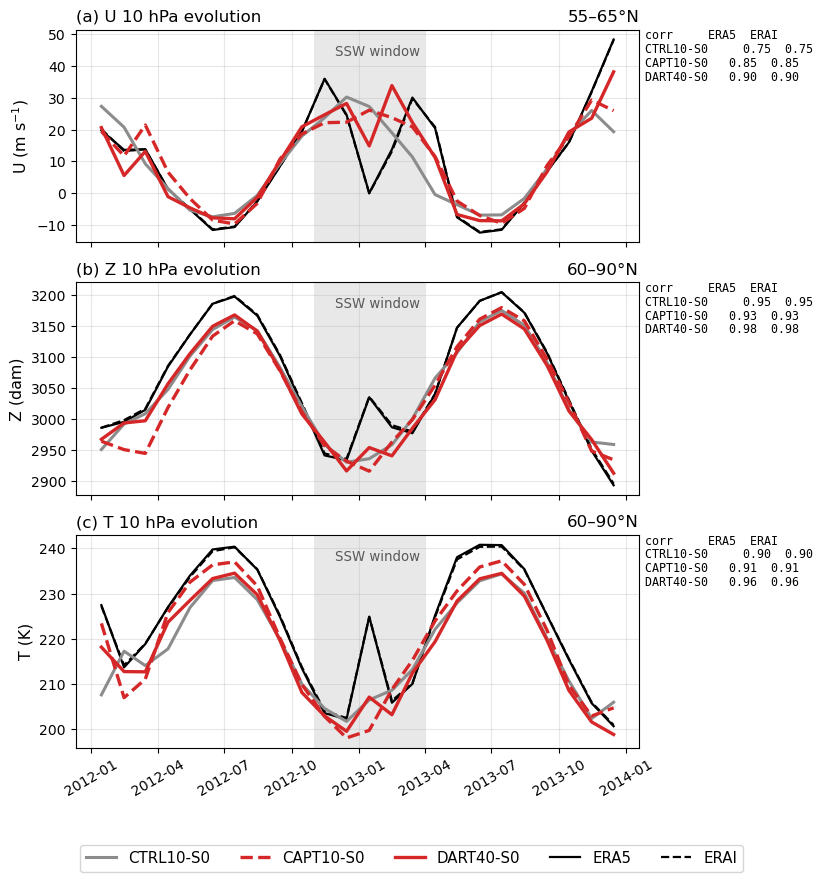

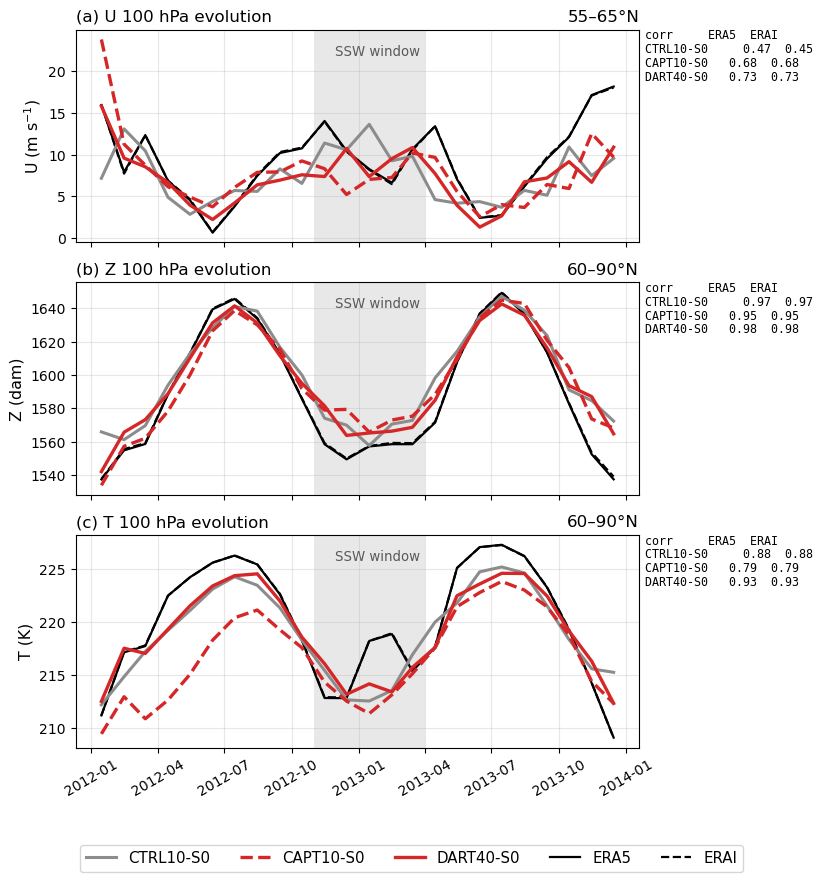

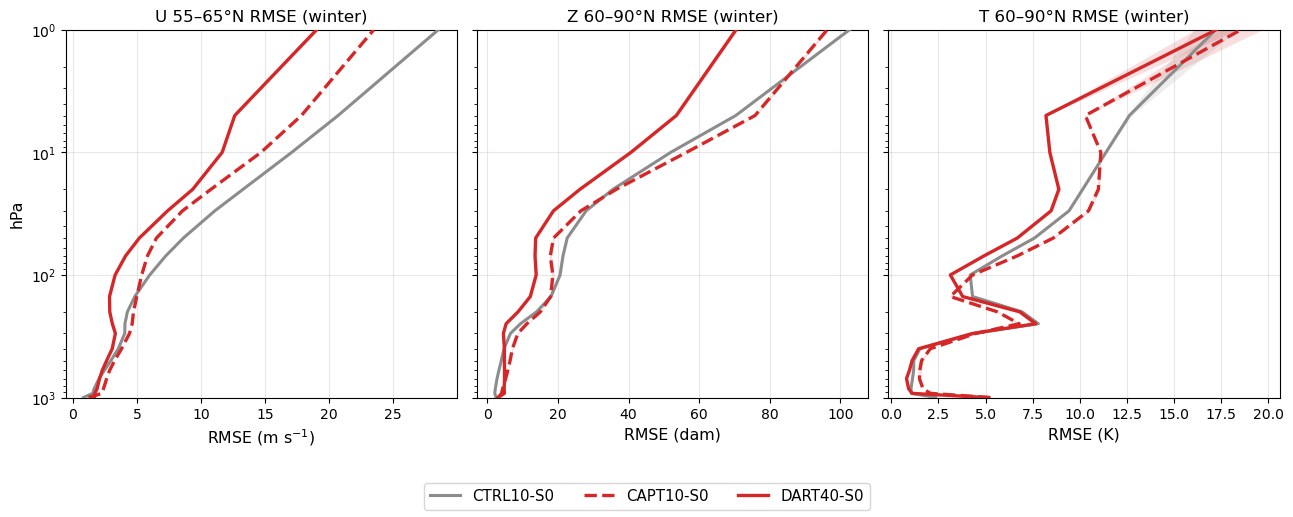

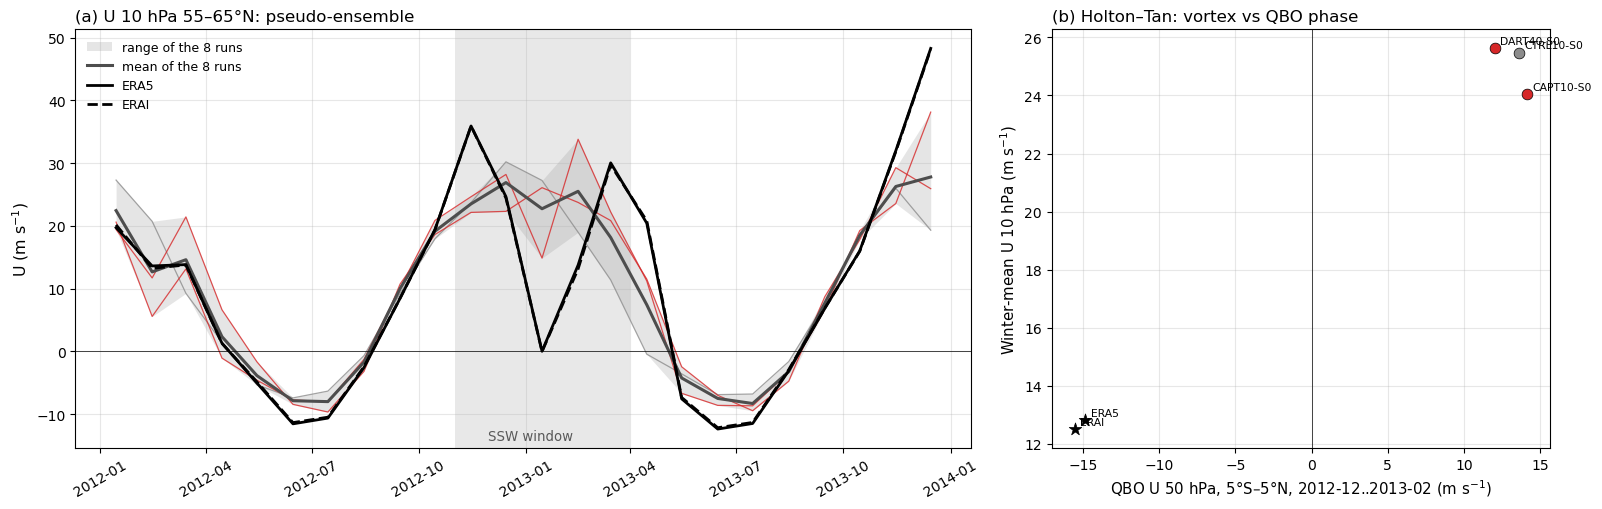

In [8]:
from util.hind_factorial import plot_factorial_scorecard

save(plotter.plot_bias_timeseries(), "ssw_bias_timeseries.png")
save(plotter.plot_bias_and_running_rmse(plevs_hpa=(10.0, 100.0), window_months=RUNNING_RMSE_MONTHS),
     "ssw_u_bias_running_rmse.png")
fig, _ = plotter.plot_rmse_attribution(p_hpa=ATTRIBUTION_LEVEL, windows=ATTRIBUTION_WINDOWS, table=attribution)
save(fig, f"ssw_attribution_u_{ATTRIBUTION_LEVEL:g}hPa.png")
for p in (10.0, 100.0):
    save(plotter.plot_evolution(p), f"ssw_evolution_{p:g}hPa.png")
save(plotter.plot_rmse_profiles("winter"), "ssw_rmse_profiles_winter.png")
save(plotter.plot_pseudo_ensemble(winter, p_hpa=ATTRIBUTION_LEVEL, qbo_level=QBO_LEVEL), "ssw_pseudo_ensemble.png")
if FACTORIAL:
    save(plot_factorial_scorecard(rmse_scores, effects, fmt="{:.1f}", higher_is_better={c: False for c in rmse_scores},
                                  title=f"U(55-65N) {ATTRIBUTION_LEVEL:g} hPa RMSE: initial-state attribution"),
         f"ssw_rmse_factorial_{ATTRIBUTION_LEVEL:g}hPa.png")